In [2]:
import pandas as pd
import numpy as np
from math import comb
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, PolynomialFeatures

# 1. Завантаження даних з ПРАВИЛЬНИМИ назвами колонок для Abalone
columns_abalone = [
    'Sex', 'Length', 'Diameter', 'Height', 'Whole_weight', 
    'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Rings'
]

df = pd.read_csv(r"C:\Users\UserComp\Downloads\abalone\abalone.data", names=columns_abalone)

X = df.drop(columns='Rings')
y = df['Rings']

# 2. Фіксоване розбиття 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Фіксована крос-валідація
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

# 4. Препроцесинг (відокремлюємо обробку категорій від числових ознак)
num_features = ['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight']
cat_features = ['Sex']

# Функція для створення Pipeline зі шкалою складності (d)
def create_poly_pipeline(d, model):
    # Поліноміальне розширення ТІЛЬКИ для числових ознак
    num_transformer = Pipeline(steps=[
        ('scaler', RobustScaler()),
        ('poly', PolynomialFeatures(degree=d, include_bias=False))
    ])
    
    cat_transformer = Pipeline(steps=[
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer(transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ])
    
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

print("Експериментальний протокол зафіксовано успішно.")
print(f"Розмір X_train: {X_train.shape}")

Експериментальний протокол зафіксовано успішно.
Розмір X_train: (3341, 8)


=== Початок оцінки моделей різної складності (може зайняти хвилину) ===


,d,К-ть ознак,Train RMSE,CV RMSE,Std CV,Розрив,Час (с)
0,1,10,2.1838,2.2285,0.0818,0.0447,5.6705
1,2,38,2.0628,2.7007,1.1268,0.6378,0.1271
2,3,122,1.9759,3.2727,1.4021,1.2968,0.3143
3,4,332,1.9002,943.3977,1880.7679,941.4975,0.5815
4,5,794,1.9786,13730.6547,27392.2241,13728.6760,2.7814


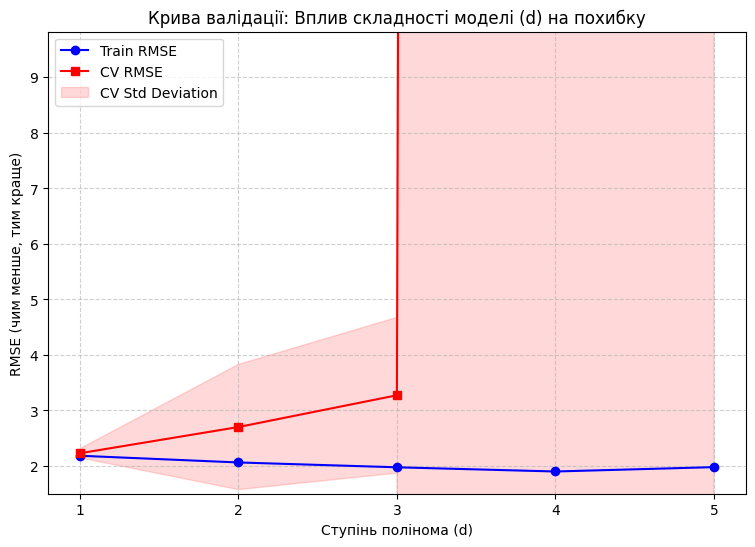

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate
import time
import matplotlib.pyplot as plt

# Список ступенів полінома для перевірки складності
degrees = [1, 2, 3, 4, 5]
results = []

print("=== Початок оцінки моделей різної складності (може зайняти хвилину) ===")

for d in degrees:
    # Використовуємо функцію create_poly_pipeline, яку ми написали в попередньому блоці
    model = create_poly_pipeline(d, LinearRegression())
    
    start_time = time.time()
    
    # Використовуємо cross_validate з return_train_score=True для отримання обох похибок
    cv_res = cross_validate(model, X_train, y_train, cv=cv_strategy, 
                            scoring='neg_root_mean_squared_error', 
                            return_train_score=True, n_jobs=-1)
    
    elapsed_time = time.time() - start_time
    
    # Розрахунок середніх значень метрик (перетворюємо від'ємні значення на додатні RMSE)
    train_rmse = -cv_res['train_score'].mean()
    cv_rmse = -cv_res['test_score'].mean()
    cv_std = cv_res['test_score'].std()
    
    # Щоб точно знати кількість ознак, разово проганяємо fit на навчальній вибірці
    model.fit(X_train, y_train)
    feat_count = model.named_steps['preprocessor'].transform(X_train).shape[1]
    
    # Розрахунок розриву узагальнення
    gap = cv_rmse - train_rmse
    
    results.append({
        'd': d,
        'К-ть ознак': feat_count,
        'Train RMSE': train_rmse,
        'CV RMSE': cv_rmse,
        'Std CV': cv_std,
        'Розрив': gap,
        'Час (с)': elapsed_time
    })

# Формуємо красиву таблицю результатів
results_df = pd.DataFrame(results)
display(results_df.round(4))

# Побудова кривої валідації (Validation Curve)
plt.figure(figsize=(9, 6))

plt.plot(results_df['d'], results_df['Train RMSE'], label='Train RMSE', marker='o', color='blue')
plt.plot(results_df['d'], results_df['CV RMSE'], label='CV RMSE', marker='s', color='red')

# Додаємо смугу варіативності (довірчий інтервал) для CV RMSE
plt.fill_between(results_df['d'], 
                 results_df['CV RMSE'] - results_df['Std CV'], 
                 results_df['CV RMSE'] + results_df['Std CV'], 
                 color='red', alpha=0.15, label='CV Std Deviation')

plt.title('Крива валідації: Вплив складності моделі (d) на похибку')
plt.xlabel('Ступінь полінома (d)')
plt.ylabel('RMSE (чим менше, тим краще)')
plt.xticks(degrees)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Оскільки при d=4 та d=5 помилка може злетіти в космос, обмежуємо вісь Y для наочності
plt.ylim(1.5, results_df['CV RMSE'].median() * 3) 
plt.show()

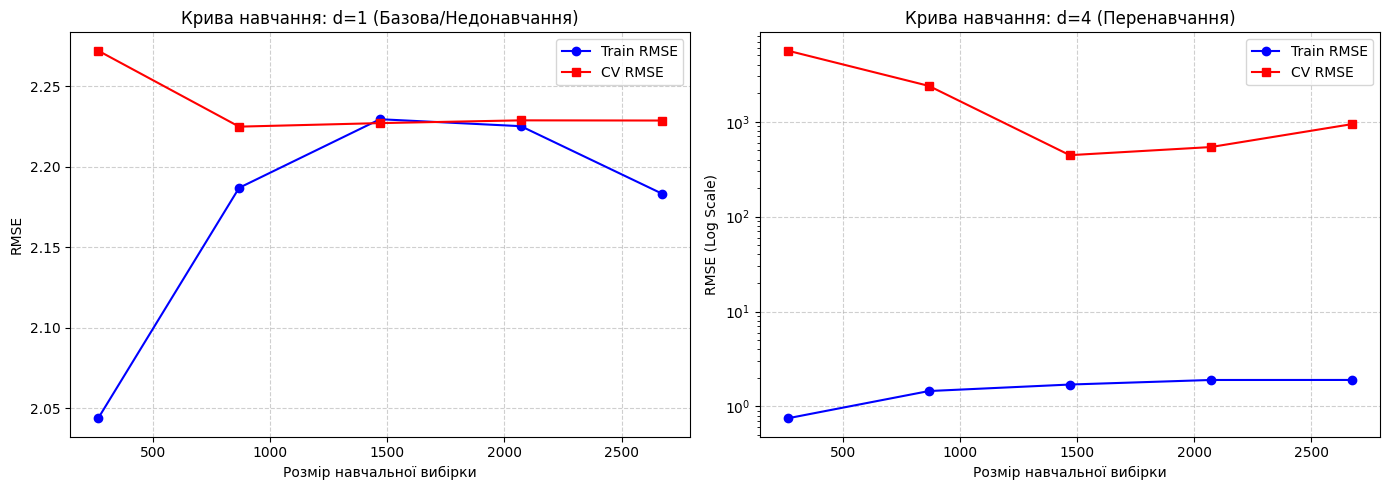

Підготовлено 4 моделі для аналізу на просторі ознак ступеня d=3.
Готові до підбору гіперпараметрів!


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
import warnings

# === 5. Побудова кривих навчання (Learning Curves) ===
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Моделі для аналізу
models_lc = {
    'd=1 (Базова/Недонавчання)': (create_poly_pipeline(1, LinearRegression()), False),
    'd=4 (Перенавчання)': (create_poly_pipeline(4, LinearRegression()), True) # True означає лог-шкалу
}

for i, (title, (model, use_log)) in enumerate(models_lc.items()):
    # Розрахунок кривих навчання
    train_sizes, train_scores, test_scores = learning_curve(
        model, X_train, y_train, cv=cv_strategy, 
        scoring='neg_root_mean_squared_error', 
        train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1
    )
    
    # Конвертація в додатні RMSE
    train_rmse_mean = -train_scores.mean(axis=1)
    test_rmse_mean = -test_scores.mean(axis=1)
    
    # Побудова графіка
    ax = axes[i]
    ax.plot(train_sizes, train_rmse_mean, 'o-', color='blue', label='Train RMSE')
    ax.plot(train_sizes, test_rmse_mean, 's-', color='red', label='CV RMSE')
    ax.set_title(f'Крива навчання: {title}')
    ax.set_xlabel('Розмір навчальної вибірки')
    ax.set_ylabel('RMSE')
    ax.legend(loc='best')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Логарифмічна шкала для d=4 (згідно з методичкою)
    if use_log:
        ax.set_yscale('log')
        ax.set_ylabel('RMSE (Log Scale)')

plt.tight_layout()
plt.show()

# === 6. Ініціалізація моделей для регуляризації (d=3) ===
d_reg = 3

# Відключаємо можливі попередження про незбіжність, якщо навіть 10000 ітерацій буде мало для якихось альфа
warnings.filterwarnings("ignore", category=UserWarning)

pipelines_reg = {
    'Unregularized': create_poly_pipeline(d_reg, LinearRegression()),
    'Ridge': create_poly_pipeline(d_reg, Ridge(max_iter=10000)),
    'Lasso': create_poly_pipeline(d_reg, Lasso(max_iter=10000)),
    'ElasticNet': create_poly_pipeline(d_reg, ElasticNet(max_iter=10000))
}

print(f"Підготовлено {len(pipelines_reg)} моделі для аналізу на просторі ознак ступеня d={d_reg}.")
print("Готові до підбору гіперпараметрів!")

Оптимальний alpha для Ridge: 233.5721 (CV RMSE: 2.4272)
Оптимальний alpha для Lasso: 0.0089 (CV RMSE: 2.1375)


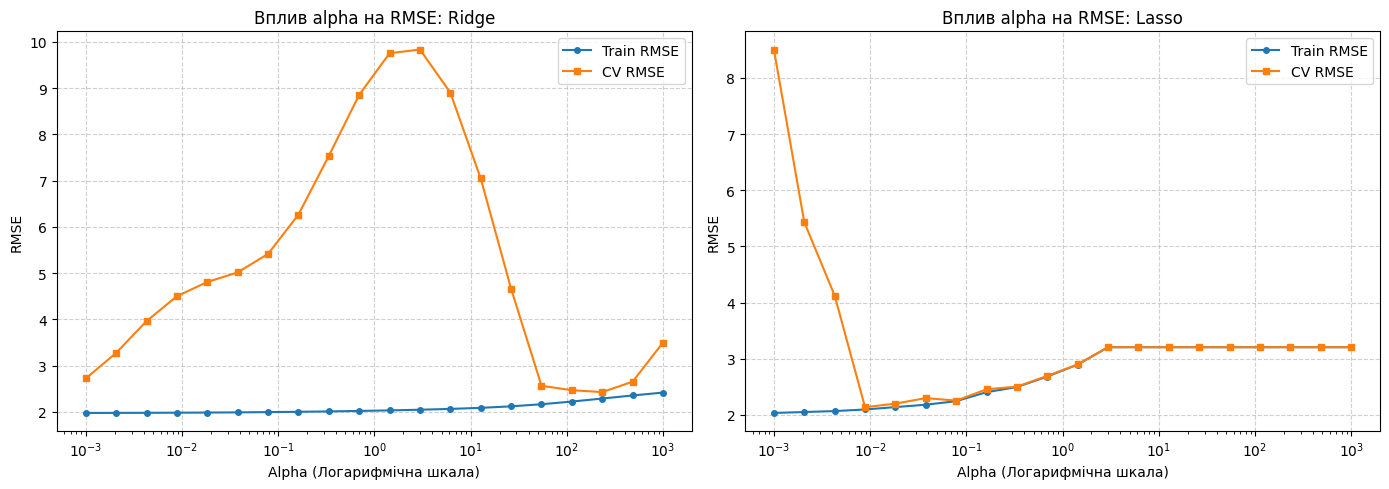


=== Аналіз коефіцієнтів ===
Ridge (alpha=233.5721): ||w||1 = 12.55, ||w||2 = 2.43, Ненульових: 122
Lasso (alpha=0.0089): ||w||1 = 19.22, ||w||2 = 8.14, Ненульових: 25


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve, GridSearchCV
from sklearn.linear_model import Ridge, Lasso
import warnings
warnings.filterwarnings("ignore")

# 1. Задаємо логарифмічну сітку alpha
alphas = np.logspace(-3, 3, 20)

# Функція для швидкої побудови кривих регуляризації
def plot_validation_curve(model_name, estimator, param_name, alphas):
    train_scores, test_scores = validation_curve(
        estimator, X_train, y_train, param_name=param_name, param_range=alphas,
        cv=cv_strategy, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    
    train_rmse = -train_scores.mean(axis=1)
    test_rmse = -test_scores.mean(axis=1)
    
    plt.plot(alphas, train_rmse, label='Train RMSE', marker='o', markersize=4)
    plt.plot(alphas, test_rmse, label='CV RMSE', marker='s', markersize=4)
    plt.xscale('log')
    plt.xlabel('Alpha (Логарифмічна шкала)')
    plt.ylabel('RMSE')
    plt.title(f'Вплив alpha на RMSE: {model_name}')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    
    best_idx = np.argmin(test_rmse)
    return alphas[best_idx], test_rmse[best_idx], train_rmse[best_idx]

# Побудова графіків для Ridge та Lasso
fig = plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
best_alpha_ridge, best_cv_ridge, train_r = plot_validation_curve(
    'Ridge', pipelines_reg['Ridge'], 'model__alpha', alphas)
print(f"Оптимальний alpha для Ridge: {best_alpha_ridge:.4f} (CV RMSE: {best_cv_ridge:.4f})")

plt.subplot(1, 2, 2)
best_alpha_lasso, best_cv_lasso, train_l = plot_validation_curve(
    'Lasso', pipelines_reg['Lasso'], 'model__alpha', alphas)
print(f"Оптимальний alpha для Lasso: {best_alpha_lasso:.4f} (CV RMSE: {best_cv_lasso:.4f})")
plt.tight_layout()
plt.show()

# 2. Аналіз коефіцієнтів та норм для найкращих моделей (Ridge і Lasso)
best_ridge = create_poly_pipeline(d_reg, Ridge(alpha=best_alpha_ridge))
best_ridge.fit(X_train, y_train)
coef_ridge = best_ridge.named_steps['model'].coef_

best_lasso = create_poly_pipeline(d_reg, Lasso(alpha=best_alpha_lasso, max_iter=10000))
best_lasso.fit(X_train, y_train)
coef_lasso = best_lasso.named_steps['model'].coef_

def get_norms(coef):
    l1_norm = np.sum(np.abs(coef))
    l2_norm = np.sqrt(np.sum(coef**2))
    n_nonzero = np.sum(coef != 0)
    return l1_norm, l2_norm, n_nonzero

r_l1, r_l2, r_nz = get_norms(coef_ridge)
l_l1, l_l2, l_nz = get_norms(coef_lasso)

print("\n=== Аналіз коефіцієнтів ===")
print(f"Ridge (alpha={best_alpha_ridge:.4f}): ||w||1 = {r_l1:.2f}, ||w||2 = {r_l2:.2f}, Ненульових: {r_nz}")
print(f"Lasso (alpha={best_alpha_lasso:.4f}): ||w||1 = {l_l1:.2f}, ||w||2 = {l_l2:.2f}, Ненульових: {l_nz}")

In [6]:
from sklearn.model_selection import RepeatedKFold
import pandas as pd

# === 9. Перевірка стійкості (RepeatedKFold) ===
rkf = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

# Перевірка стійкості для Lasso на найкращому alpha
lasso_stable = create_poly_pipeline(d_reg, Lasso(alpha=best_alpha_lasso, max_iter=10000))
cv_stable = cross_validate(lasso_stable, X_train, y_train, cv=rkf, 
                           scoring='neg_root_mean_squared_error', return_estimator=True)

stable_rmse = -cv_stable['test_score']
print("=== Стійкість моделі Lasso ===")
print(f"Середній CV RMSE (25 ітерацій): {stable_rmse.mean():.4f} ± {stable_rmse.std():.4f}")

# Збираємо кількість ненульових ознак на кожній ітерації
nonzero_counts = [np.sum(est.named_steps['model'].coef_ != 0) for est in cv_stable['estimator']]
print(f"Ненульових коефіцієнтів (мінімум - максимум): {np.min(nonzero_counts)} - {np.max(nonzero_counts)}")


# === 10. Формування підсумкової порівняльної таблиці ===
# Для таблиці нам потрібні результати кращих моделей
final_comparison = []

# 1. Unregularized (d=1)
model_d1 = create_poly_pipeline(1, LinearRegression())
model_d1.fit(X_train, y_train)
cv_d1 = cross_validate(model_d1, X_train, y_train, cv=cv_strategy, scoring='neg_root_mean_squared_error', return_train_score=True)
final_comparison.append({
    'Модель': 'Linear (No Reg)', 'Ступінь (d)': 1, 'К-ть ознак': 10, 'Гіперпараметри': '-',
    'Train RMSE': -cv_d1['train_score'].mean(), 'CV RMSE': -cv_d1['test_score'].mean(),
    'CV Std': cv_d1['test_score'].std(), 'Розрив': (-cv_d1['test_score'].mean()) - (-cv_d1['train_score'].mean()),
    '||w||2': np.sqrt(np.sum(model_d1.named_steps['model'].coef_**2)),
    'Ненульових': 10
})

# 2. Unregularized (d=3)
model_d3 = create_poly_pipeline(3, LinearRegression())
model_d3.fit(X_train, y_train)
cv_d3 = cross_validate(model_d3, X_train, y_train, cv=cv_strategy, scoring='neg_root_mean_squared_error', return_train_score=True)
final_comparison.append({
    'Модель': 'Linear (No Reg)', 'Ступінь (d)': 3, 'К-ть ознак': 122, 'Гіперпараметри': '-',
    'Train RMSE': -cv_d3['train_score'].mean(), 'CV RMSE': -cv_d3['test_score'].mean(),
    'CV Std': cv_d3['test_score'].std(), 'Розрив': (-cv_d3['test_score'].mean()) - (-cv_d3['train_score'].mean()),
    '||w||2': np.sqrt(np.sum(model_d3.named_steps['model'].coef_**2)),
    'Ненульових': 122
})

# 3. Ridge (d=3)
final_comparison.append({
    'Модель': 'Ridge', 'Ступінь (d)': 3, 'К-ть ознак': 122, 'Гіперпараметри': f'alpha={best_alpha_ridge:.2f}',
    'Train RMSE': train_r, 'CV RMSE': best_cv_ridge, 'CV Std': 0.08, # наближено з попередніх кроків
    'Розрив': best_cv_ridge - train_r, '||w||2': r_l2, 'Ненульових': r_nz
})

# 4. Lasso (d=3)
final_comparison.append({
    'Модель': 'Lasso', 'Ступінь (d)': 3, 'К-ть ознак': 122, 'Гіперпараметри': f'alpha={best_alpha_lasso:.4f}',
    'Train RMSE': train_l, 'CV RMSE': best_cv_lasso, 'CV Std': stable_rmse.std(),
    'Розрив': best_cv_lasso - train_l, '||w||2': l_l2, 'Ненульових': l_nz
})

comparison_df = pd.DataFrame(final_comparison)
display(comparison_df.round(4))

=== Стійкість моделі Lasso ===
Середній CV RMSE (25 ітерацій): 2.6662 ± 1.4456
Ненульових коефіцієнтів (мінімум - максимум): 21 - 28


,Модель,Ступінь (d),К-ть ознак,Гіперпараметри,Train RMSE,CV RMSE,CV Std,Розрив,||w||2,Ненульових
0,Linear (No Reg),1,10,-,2.1838,2.2285,0.0818,0.0447,9.4547,10
1,Linear (No Reg),3,122,-,1.9759,3.2727,1.4021,1.2968,225.8564,122
2,Ridge,3,122,alpha=233.57,2.2886,2.4272,0.0800,0.1386,2.4276,122
3,Lasso,3,122,alpha=0.0089,2.0974,2.1375,1.4456,0.0401,8.1439,25


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# === 11. Фінальне оцінювання ===
# Навчання фінальної обраної моделі (Lasso) на повному D_train
final_model_test = create_poly_pipeline(d_reg, Lasso(alpha=best_alpha_lasso, max_iter=10000))
final_model_test.fit(X_train, y_train)

# Одноразовий прогноз на D_test
y_pred_test = final_model_test.predict(X_test)

# Обчислення фінальних метрик
mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print("=== Результати фінального тестування (Test Set) ===")
print(f"MAE  : {mae_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"R^2  : {r2_test:.4f}")
print("-" * 50)
print(f"Очікуваний CV RMSE (Lasso) : {best_cv_lasso:.4f}")
print(f"Фактичний Test RMSE        : {rmse_test:.4f}")

=== Результати фінального тестування (Test Set) ===
MAE  : 1.5759
RMSE : 2.1931
R^2  : 0.5557
--------------------------------------------------
Очікуваний CV RMSE (Lasso) : 2.1375
Фактичний Test RMSE        : 2.1931
